# Setup

In [8]:
# Load necessary packages. 
suppressPackageStartupMessages({library(ggplot2)
library(dplyr)
library(tidyr)
library(scales)
library(tibble)
library(svglite)
library(stringr)
})

In [9]:
# Load in summary tables.
flipper = read.delim("results/flipper_results_summary.tsv", row.names=1, check.names=FALSE) %>% mutate(algorithm="Flipper")
adhoc = read.delim("results/adhoc_results_summary.tsv", row.names=1, check.names=FALSE)  %>% mutate(algorithm="Ad-hoc")
diffskip = read.delim("results/diffskip_results_summary.tsv", row.names=1, check.names=FALSE) %>% mutate(algorithm="Diff-Skipper")

# Process data

In [10]:
# Combine into one data.frame
df_combined = bind_rows(flipper, adhoc, diffskip)

# Extract numeric parts from folder names.
df2 = df_combined %>% mutate(beta_val = as.numeric(str_match(folder, "beta_([0-9\\.]+)")[,2]),
                             rep_val  = as.integer(str_match(folder, "rep([0-9]+)$")[,2]),
                             expression_effect = factor(beta_val,levels = c(0, 2),
                                                        labels = c("No Expression Effect", "Expression Effect")))

# Make plot

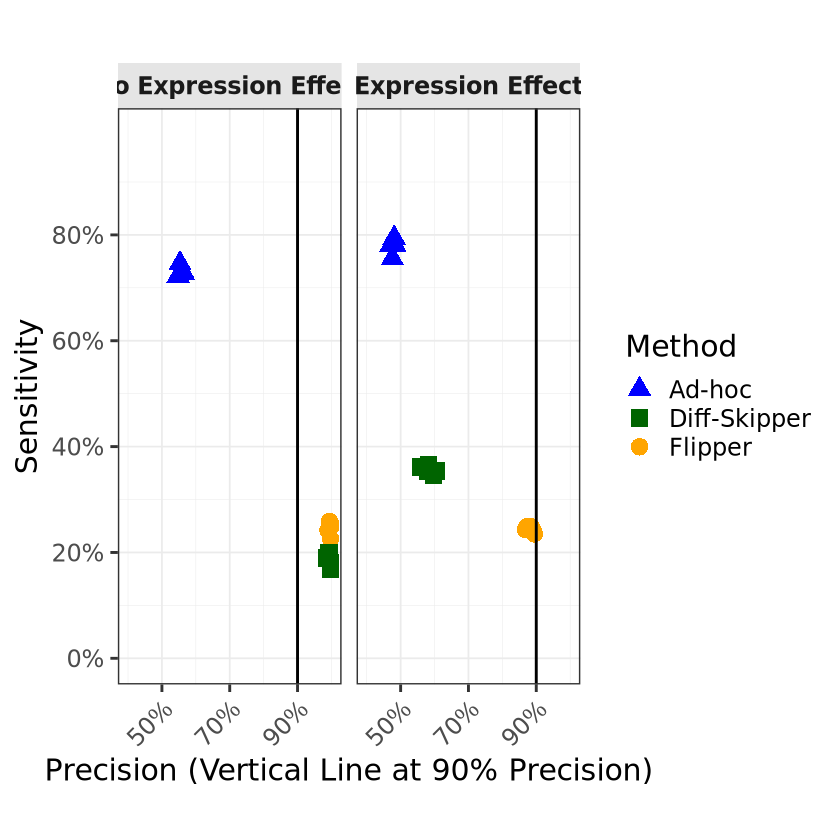

In [11]:
# 4) Plot precision vs sensitivity for all three methods
p = ggplot(df2, aes(x = precision, y = sensitivity, color = algorithm, shape = algorithm)) +
    geom_point(size = 4.4) + geom_vline(xintercept = 0.9, color = "black") +
    scale_x_continuous(limits = c(0.4, 1.0), breaks = seq(0.1, 1.0, by = 0.2), 
                       minor_breaks = seq(0.4, 1.0, by = 0.1), labels = percent_format(accuracy = 1)) +
    scale_y_continuous(limits = c(0, 0.99),breaks = seq(0, 0.99, by = 0.2),
                       minor_breaks = seq(0, 0.99, by = 0.1), labels = percent_format(accuracy = 1)) +
    facet_grid(~expression_effect) + 
    scale_color_manual(name = "Method",values = c("Flipper" = "orange", "Ad-hoc" = "blue", "Diff-Skipper" = "darkgreen")) +
    scale_shape_manual(name = "Method", values = c("Flipper" = 16, "Ad-hoc" = 17, "Diff-Skipper" = 15)) +
    theme_bw(base_size = 18) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), strip.background = element_rect(fill = "grey90", color = NA),
          strip.text = element_text(face = "bold"), panel.grid.major = element_line(linewidth = 0.50), 
          panel.grid.minor = element_line(linewidth = 0.15)) +
    labs(title = "", x = "Precision (Vertical Line at 90% Precision)", y = "Sensitivity", caption = "")

# Save and print plot.
ggsave("plot.svg", p, device = "svg", width = 10, height = 5)
print(p)